# Occupancy Sensing using OFDM Channel Estimation
Names: Marc Pham


In [1]:
from pathlib import Path
import json
import os
import sys
import numpy as np
import pickle
from IPython.display import Image, display
import IPython.core.pylabtools as pylabtools
import matplotlib.pyplot as plt

# Matplotlib 3.6 expects this compatibility table, which newer IPython omits.
if not hasattr(pylabtools, "backend2gui"):
    pylabtools.backend2gui = {}

def locate_lab_root():
    for base in (Path.cwd(), *Path.cwd().parents):
        if (base / "support" / "lab5_dsp.py").is_file():
            return base
    raise FileNotFoundError("Open this notebook from its Lab 5 folder.")

LAB_ROOT = locate_lab_root()
sys.path.insert(0, str(LAB_ROOT / "support"))
WORK_DIR = LAB_ROOT / "work"
FIGURE_DIR = WORK_DIR / "figures"
WAVEFORM_DIR = WORK_DIR / "waveforms"
CAPTURE_DIR = Path(os.environ.get("ECE7377_LAB5_CAPTURE_DIR", WORK_DIR / "captures"))
for path in (FIGURE_DIR, WAVEFORM_DIR, CAPTURE_DIR):
    path.mkdir(parents=True, exist_ok=True)

import lab5_dsp as lab
import lab5_tools

print("Lab root:", LAB_ROOT)
print("Capture directory:", CAPTURE_DIR)


Lab root: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/OccupancySensing
Capture directory: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/OccupancySensing/work/captures


## Finite-file and capture calculations


The sample rate of 1 MS/s, center frequency of 2.45 GHz, period length of 8192 samples, and one warm-up period were kept the same as Lab 5 to preserve the validated OFDM waveform, synchronization process, and channel-estimation receiver without requiring modification of the underlying signal-processing chain. The repeat count was increased from 13 to 50 periods to provide 49 usable channel estimates per capture, improving the statistical robustness of the occupancy-sensing analysis by allowing channel estimates to be averaged and compared across many observations. The acquisition lead was reduced from 2,000,000 samples to 250,000 samples (2 s to 0.25 s) because only a short delay is needed to ensure the receiver is recording before transmission begins. Similarly, the capture duration was reduced from 15 s to 5 s since the transmitted OFDM burst occupies less than one second, significantly reducing file size and data-processing requirements while still providing ample margin to capture the complete transmission.

In [2]:
sample_rate_sps = 1_000_000
period_samples = 8192
repeat_count = 50
warmup_periods = 1
acquisition_lead_samples = 250_000
capture_seconds = 5.0
center_frequency_hz = 2_450_000_000.0

# Exact counts
payload_burst_samples = repeat_count * period_sçamples
transmit_samples = acquisition_lead_samples + payload_burst_samples
transmit_bytes = transmit_samples * 8          # complex64

capture_samples = int(capture_seconds * sample_rate_sps)
capture_bytes = capture_samples * 8            # complex64

expected_frames = repeat_count - warmup_periods

print("OFDM burst samples:", payload_burst_samples)
print("guarded TX samples and bytes:", transmit_samples, transmit_bytes)
print("RX samples and bytes:", capture_samples, capture_bytes)
print("graded frames:", expected_frames)

OFDM burst samples: 409600
guarded TX samples and bytes: 659600 5276800
RX samples and bytes: 5000000 40000000
graded frames: 49


## Build the finite transmitter file and metadata


Updated the prepare_hardware_experiment() code to only take a set tx_gains because we don't need to test the different combinations there.

In [3]:
tx_gains_db = 50
rx_gain_db = 60

prepared = lab5_tools.prepare_hardware_experiment(WAVEFORM_DIR, CAPTURE_DIR, tx_gains_db, rx_gain_db,
                                                  sample_rate_sps, center_frequency_hz, repeat_count,
                                                  acquisition_lead_samples, capture_seconds)
print(json.dumps(prepared, indent=2))

{
  "waveform_path": "/home/mepham/ECE7377/OccupancySensing/work/waveforms/tx_pilot_file.dat",
  "waveform_bytes": 5276800,
  "summary_path": "/home/mepham/ECE7377/OccupancySensing/work/captures/lab5_measurement_summary.json",
  "summary": {
    "waveform": {
      "tx_gains_db": 50,
      "measurement_periods": 49,
      "warmup_periods": 1,
      "repeat_count": 50,
      "capture_duration_s": 5.0,
      "capture_samples": 5000000,
      "sample_rate_sps": 1000000,
      "center_frequency_hz": 2450000000.0,
      "rx_gain_db": 60.0,
      "period_samples": 8192,
      "active_frame_samples": 2080,
      "acquisition_lead_samples": 250000,
      "finite_tx_samples": 659600,
      "digital_peak": 0.10000000149011612,
      "period_sha256": "a1e8eceb01c8c6d9eeb0d374cd2cbb2668a17f9f90a3f828317c2bfe7094eaba",
      "file_sha256": "2570d029151b0a70948dd1d969be9740162c14c2e7767128b78398f58065132f"
    }
  }
}


In [4]:
!ls -la $WAVEFORM_DIR/tx_pilot_file.dat

-rw-r--r-- 1 mepham mepham 5276800 Nov  3 16:14 /home/mepham/ECE7377/OccupancySensing/work/waveforms/tx_pilot_file.dat


## GNU Radio acquisition


### Transmitter Flowgraph

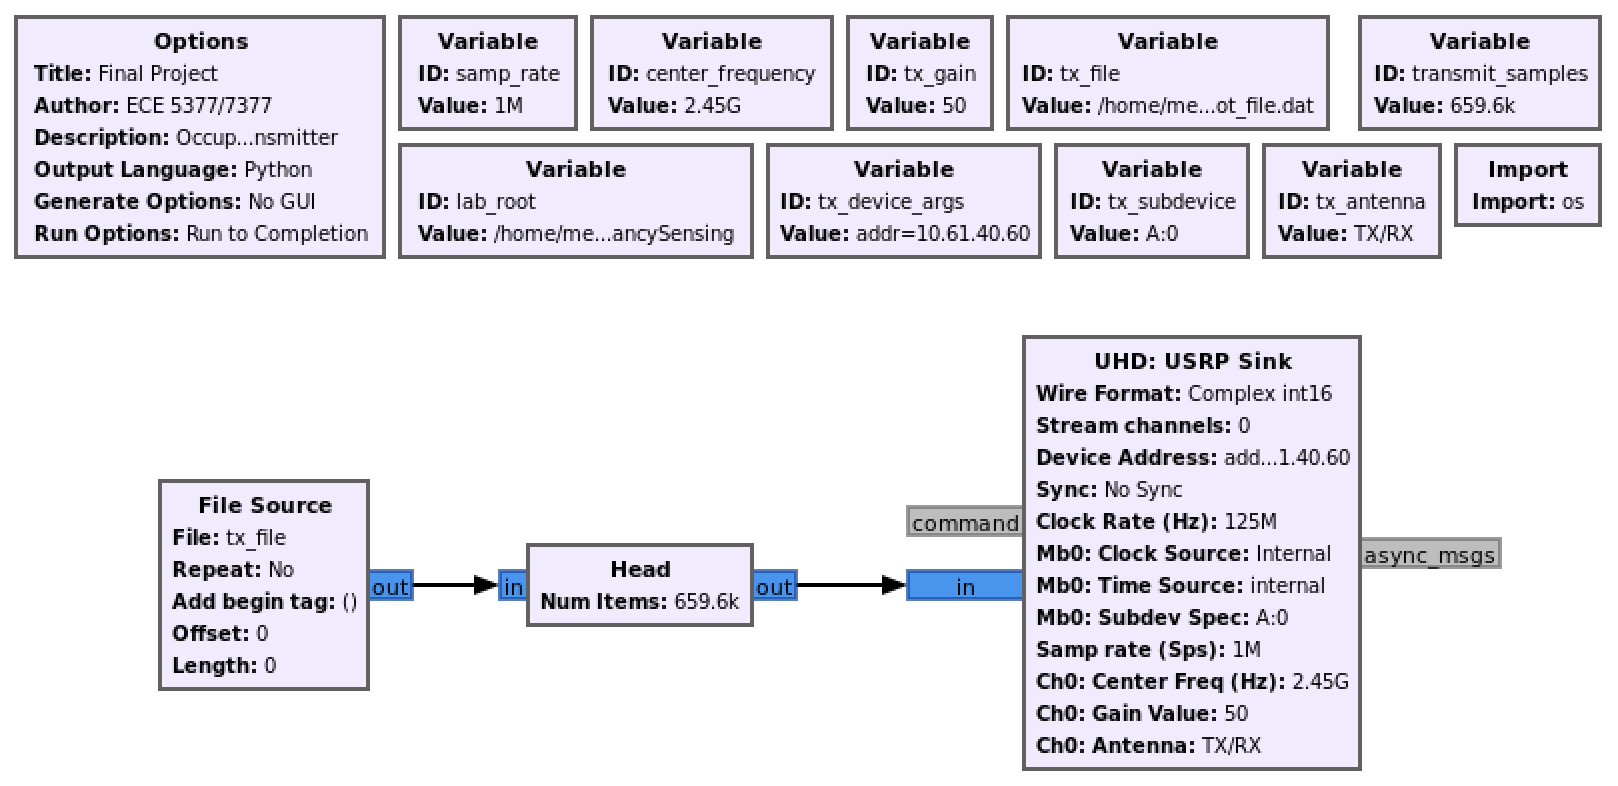

### Receiver Flowgraph

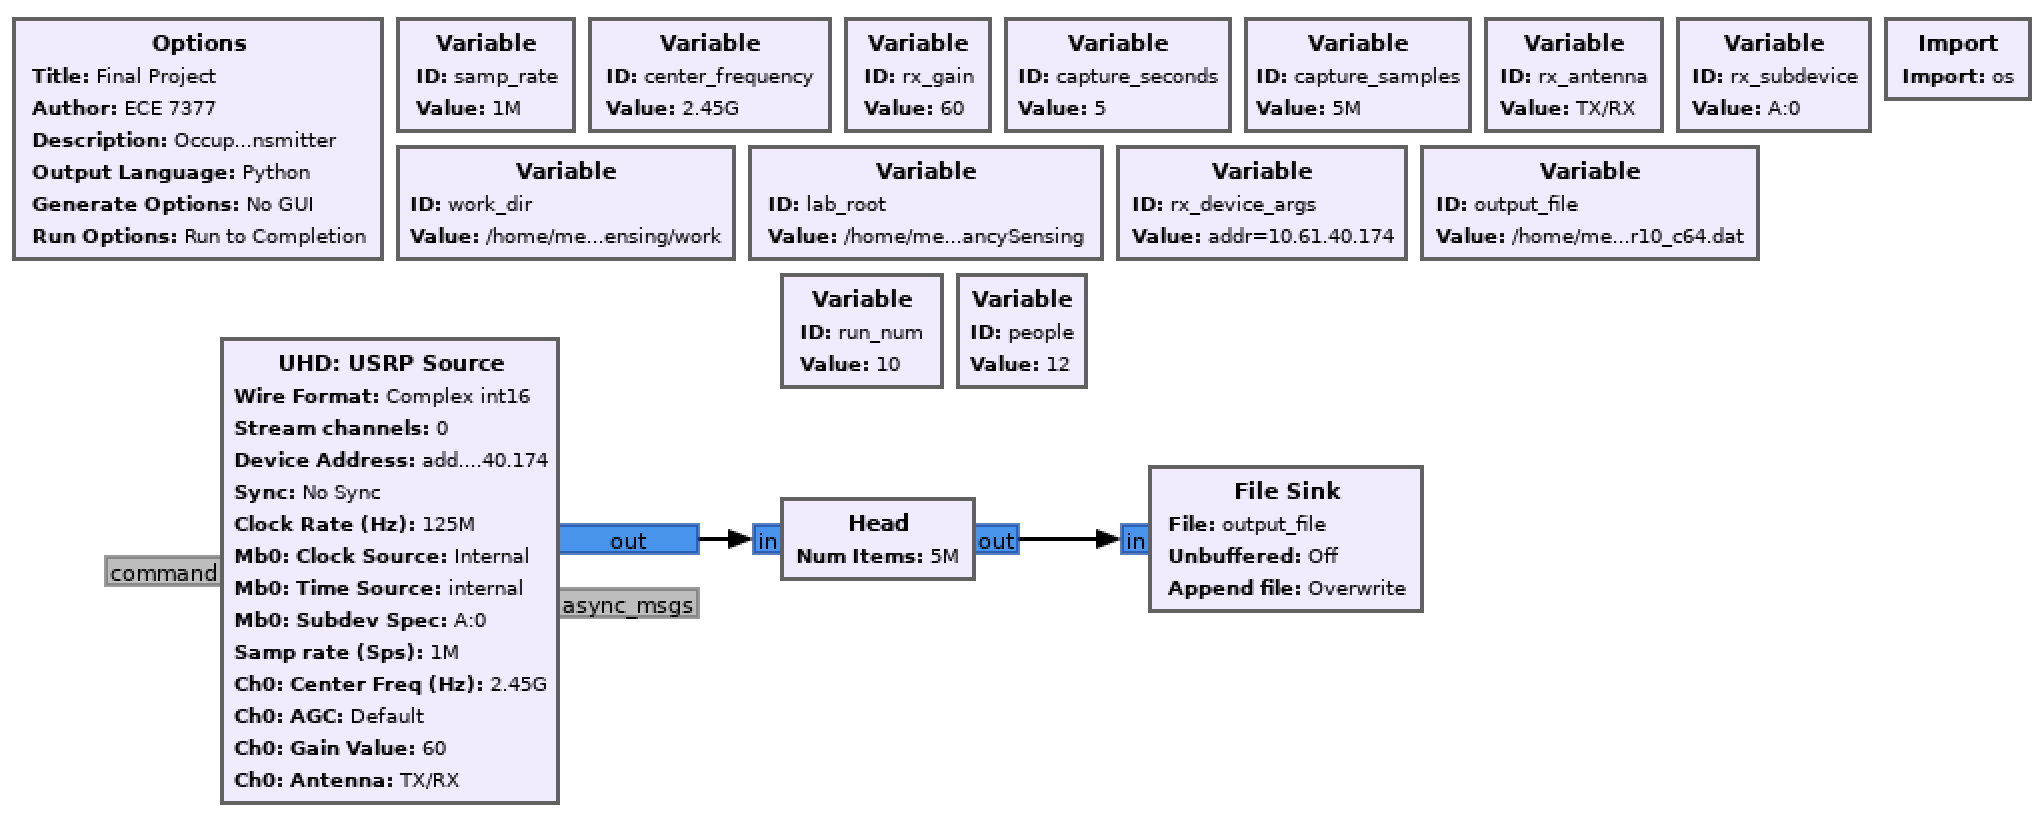

## Results

File Names: occupancy_p(Number of People)_r(Run Number)_c64.dat

### Channel Estimates

In [4]:
# Calculates the channel estimates for every measurement run.
results = lab5_tools.analyze_all_channel_estimates(CAPTURE_DIR)

/Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/OccupancySensing/work/captures/occupancy_p0_r10_c64.dat
/Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/OccupancySensing/work/captures/occupancy_p0_r1_c64.dat
/Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/OccupancySensing/work/captures/occupancy_p0_r2_c64.dat
/Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/OccupancySensing/work/captures/occupancy_p0_r3_c64.dat
/Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/OccupancySensing/work/captures/occupancy_p0_r4_c64.dat
/Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/OccupancySensing/work/captures/occupancy_p0_r5_c64.dat
/Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/OccupancySensing/work/captures/occupancy_p0_r6_c64.dat
/Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/OccupancySensing/work/captures/occupancy_p0_r7_c64.dat
/Users/

In [5]:
# Saves new results
CACHE_FILE = "results.pkl"
with open(CACHE_FILE, "wb") as f:
    pickle.dump(results, f)

In [2]:
# Loads the saved results
CACHE_FILE = "results.pkl"
with open(CACHE_FILE, "rb") as f:
    results = pickle.load(f)

### Normalized Complex Correlation Heatmap

0 vs 0 average correlation:   0.9630
12 vs 12 average correlation: 0.9617
0 vs 12 average correlation:  0.9610

Welch t-tests
0vs0 vs 0vs12: TtestResult(statistic=0.3553190558129746, pvalue=0.7227498442535885, df=187.55891476059892)
12vs12 vs 0vs12: TtestResult(statistic=0.1195127471543388, pvalue=0.9050017173251094, df=180.96018877744632)
0vs0 vs 12vs12: TtestResult(statistic=0.20065790313392728, pvalue=0.8411954991800606, df=177.74099662303595)


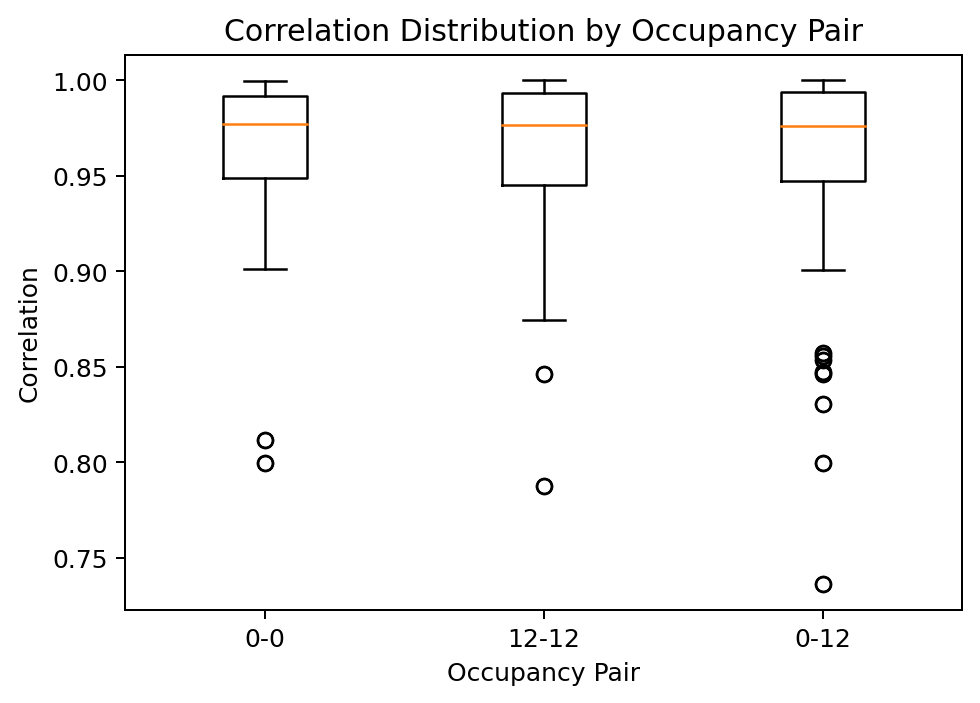

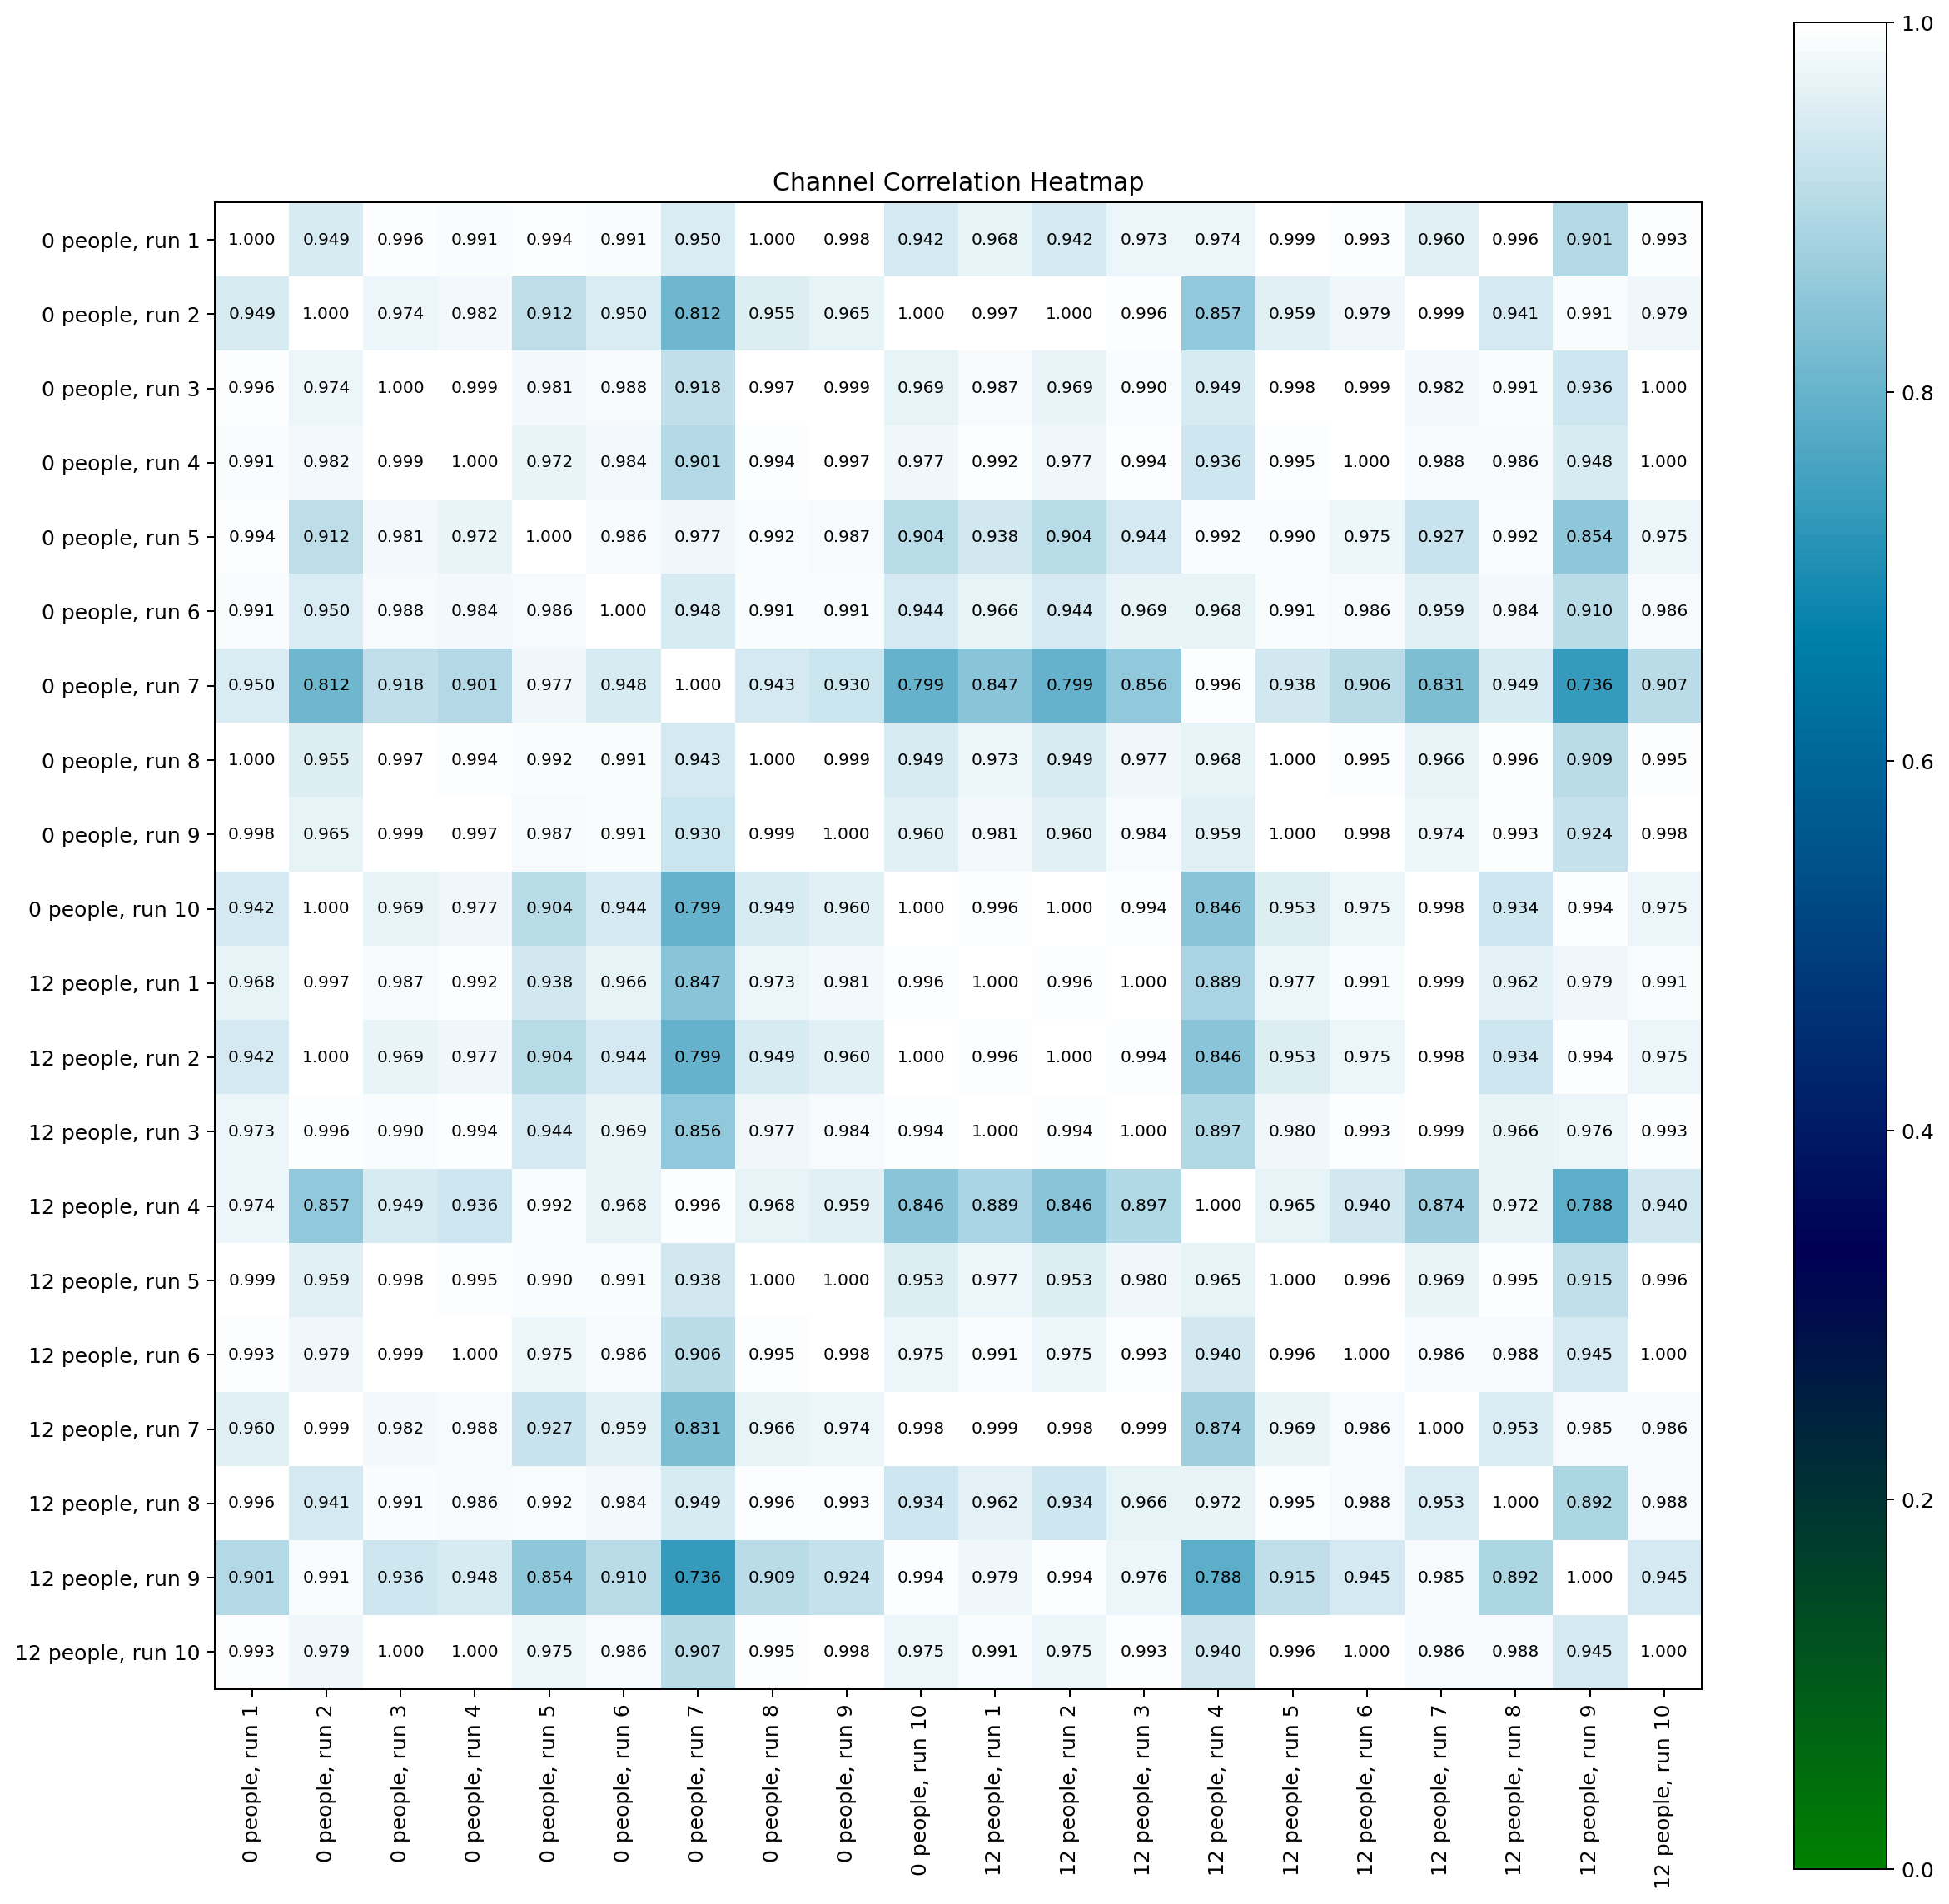

In [3]:
lab5_tools.plot_correlation_heatmap(results, FIGURE_DIR)
for name in {'occupancy_corr_heatmap', 'occupancy_corr_boxplot'}:
    path = FIGURE_DIR / f"{name}.png"
    display(Image(filename=path))

### Channel Magnitude Plot


Mean magnitude comparison
0 people : -57.2679
12 people: -59.6632
TtestResult(statistic=0.9317301826651097, pvalue=0.3638056128834972, df=18.0)


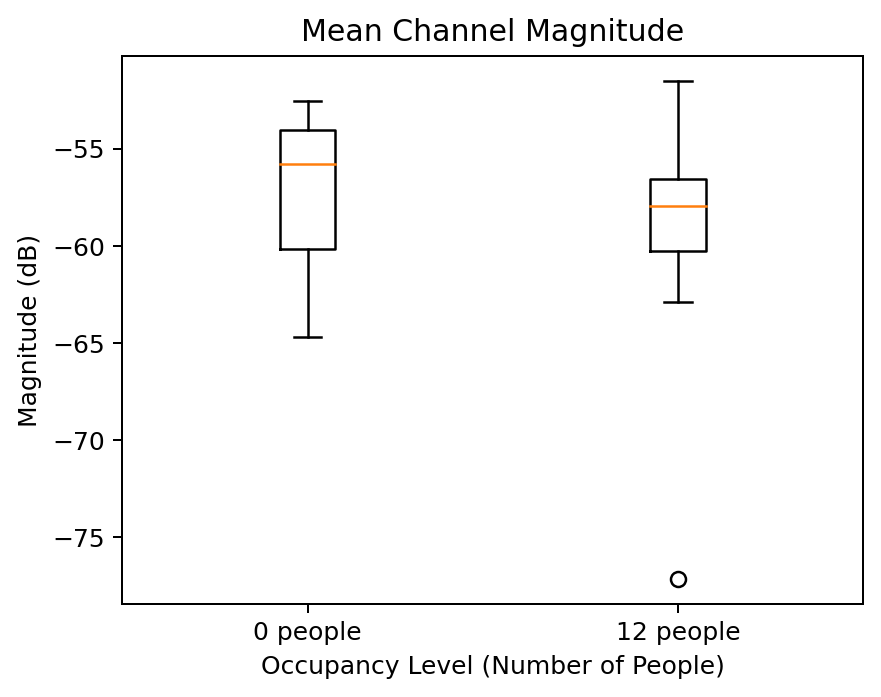

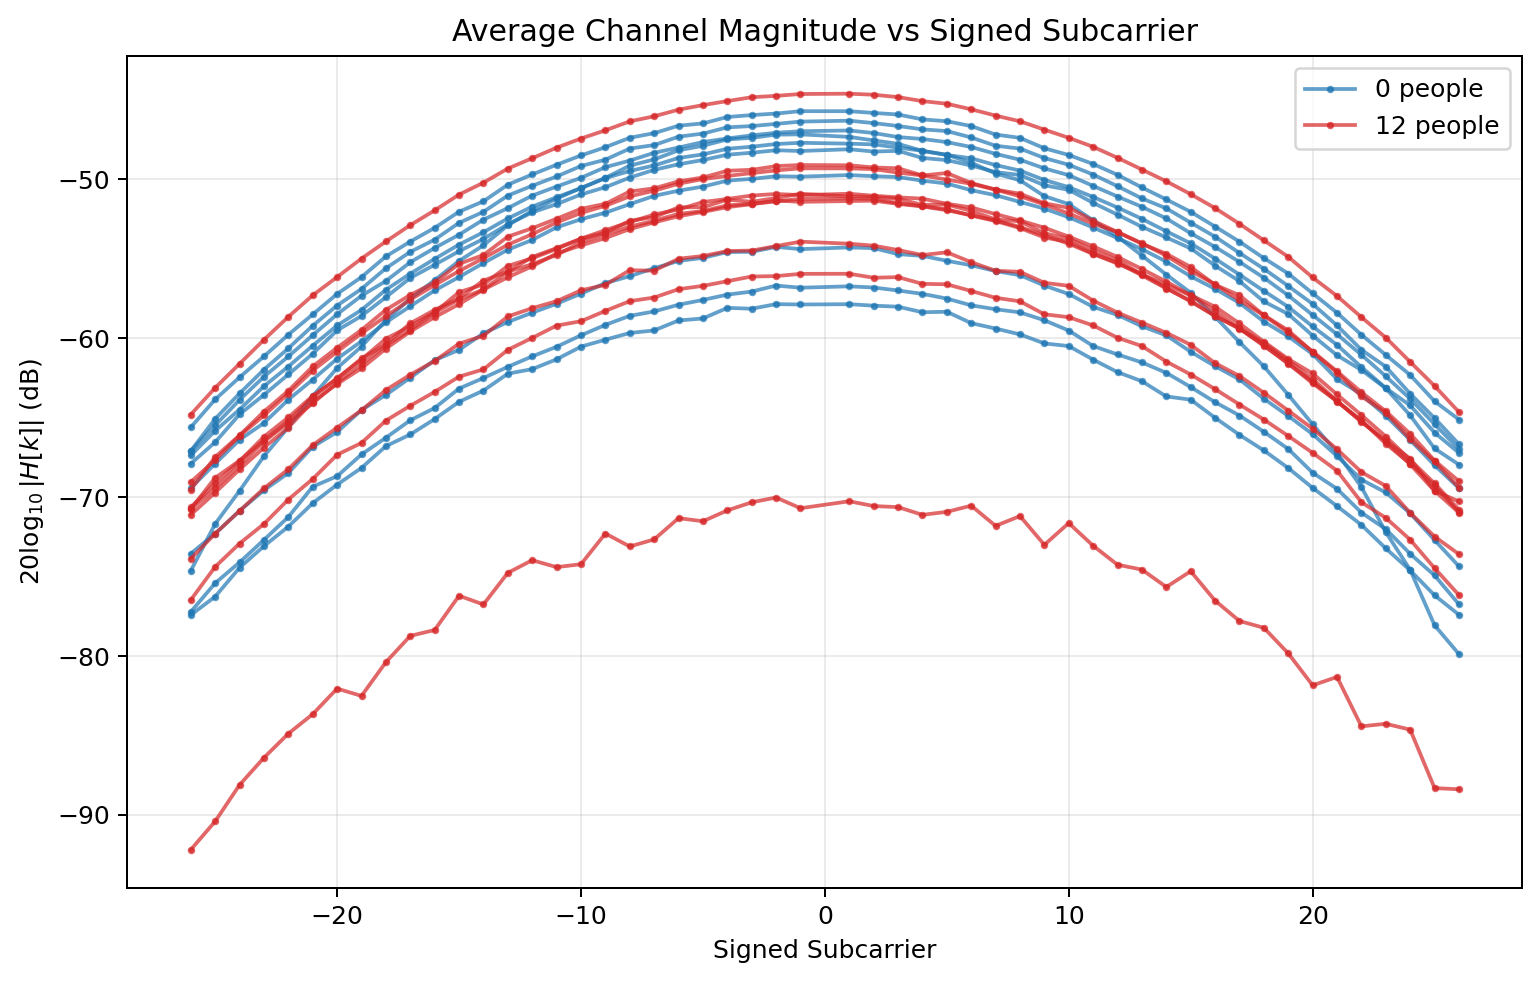

In [4]:
lab5_tools.plot_channel_magnitude(results, FIGURE_DIR)
for name in {'occupancy_channel_magnitude', 'occupancy_magnitude_mean'}:
    path = FIGURE_DIR / f"{name}.png"
    display(Image(filename=path))

### Channel Phase Plot


Mean phase comparison
0 people : -9.7380
12 people: -10.8400
TtestResult(statistic=1.1572589522405243, pvalue=0.26229355858575204, df=18.0)


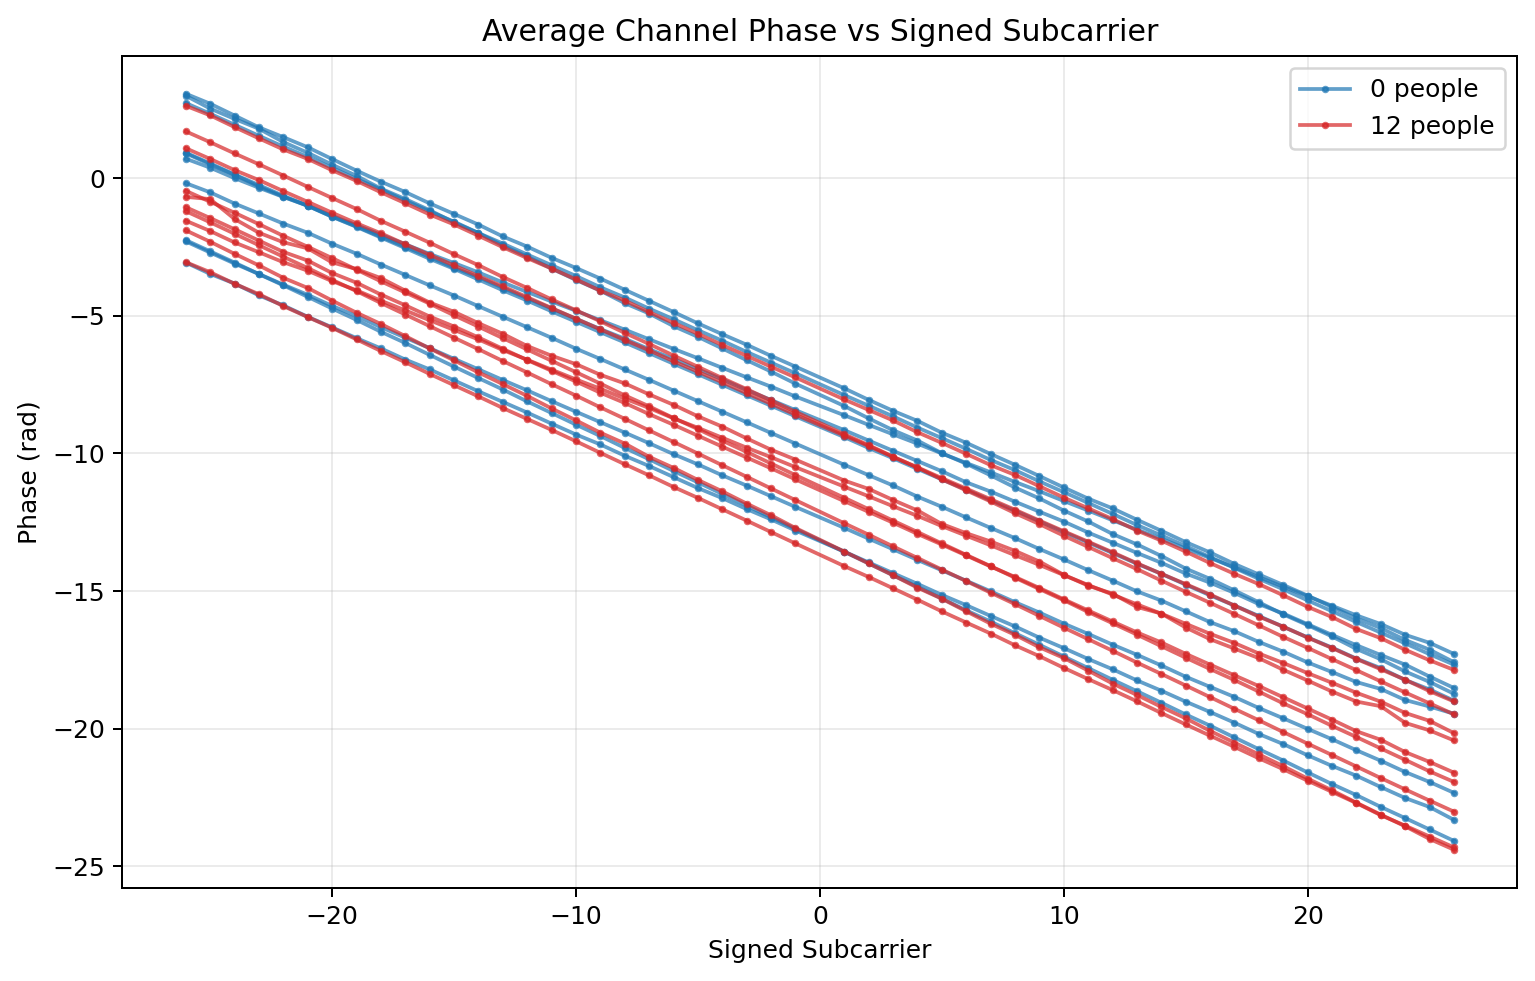

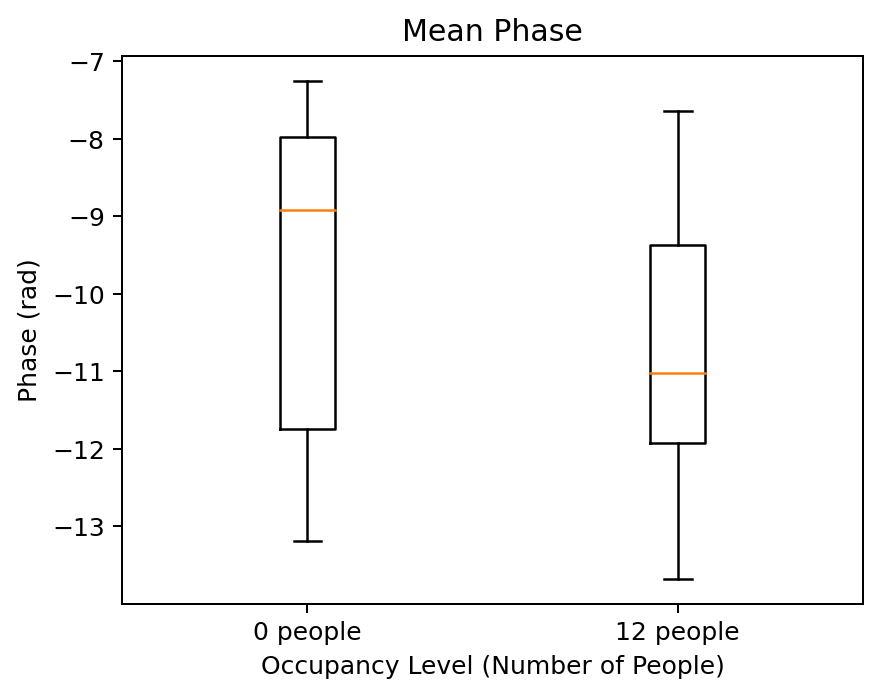

In [5]:
lab5_tools.plot_channel_phase(results, FIGURE_DIR)
for name in {'occupancy_channel_phase', 'occupancy_phase_features'}:
    path = FIGURE_DIR / f"{name}.png"
    display(Image(filename=path))
